In [3]:
!git clone -q https://github.com/esa/SpOC2.git
%cd "/kaggle/working/SpOC2/Morphing Rovers"
!mkdir -p data/spoc2/morphing && cp -r data/Maps data/coordinates.txt data/example_rover.npy data/spoc2/morphing/
!sed -i "77s/.*/HEIGHTMAP_NAMES = ['Map1.jpg', 'Map2.jpg', 'Map3.jpg', 'Map4.jpg', 'Map5.jpg', 'Map6.jpg']/" morphing_udp.py
!sed -i '683s/, angle,/, float(angle),/' morphing_udp.py
!pip install -q cma

/kaggle/working/SpOC2/Morphing Rovers


In [4]:
!wget -q -O fillimi.npy https://raw.githubusercontent.com/vesabraina/VesaBraina-MorphingRovers/main/checkpoints/ga_best.npy
import numpy as np, time, cma
import matplotlib.pyplot as plt
from morphing_udp import morphing_rover_UDP

udp = morphing_rover_UDP()
lb, ub = map(np.array, udp.get_bounds())
x0 = np.load("fillimi.npy")
nota0 = udp.fitness(x0)[0]
print("Nota e fillimit:", round(nota0, 3))

Nota e fillimit: 4.828


In [7]:
n = len(x0) - 7
x_int = x0[-7:]

def bej_rover(z):
    return np.concatenate([np.clip(z, lb[:n], ub[:n]), x_int])

es = cma.CMAEvolutionStrategy(x0[:n], 0.02,
        {"CMA_diagonal": True, "popsize": 6, "seed": 42, "verbose": -9})

historia = [nota0]
me_e_mira, x_best = nota0, x0.copy()
t = time.time()
for g in range(1, 6):
    Z = es.ask()
    notat = [udp.fitness(bej_rover(z))[0] for z in Z]
    es.tell(Z, notat)
    i = int(np.argmin(notat))
    if notat[i] < me_e_mira:
        me_e_mira, x_best = notat[i], bej_rover(Z[i])
    historia.append(me_e_mira)
    print(f"Gjenerata {g}: më e mira {me_e_mira:.3f}, mesatarja {np.mean(notat):.3f}, hapi {es.sigma:.3f}")
print("Koha:", round(time.time() - t), "sekonda")

Gjenerata 1: më e mira 4.743, mesatarja 6.085, hapi 0.020
Gjenerata 2: më e mira 4.683, mesatarja 5.501, hapi 0.021
Gjenerata 3: më e mira 4.618, mesatarja 5.704, hapi 0.021
Gjenerata 4: më e mira 4.618, mesatarja 5.744, hapi 0.021
Gjenerata 5: më e mira 4.618, mesatarja 5.520, hapi 0.021
Koha: 818 sekonda


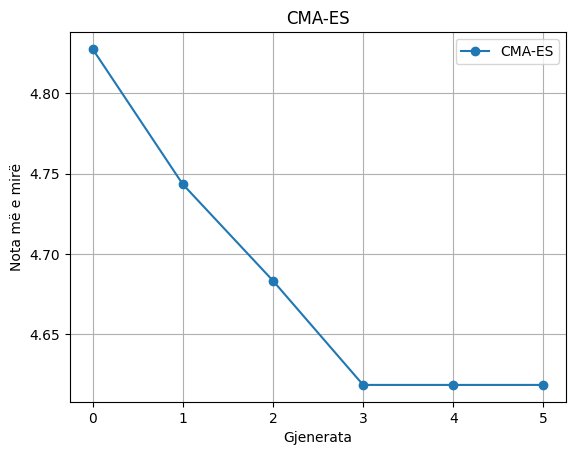

Nota finale: 4.618


In [9]:
plt.plot(range(len(historia)), historia, marker="o", label="CMA-ES")
plt.xlabel("Gjenerata"); plt.ylabel("Nota më e mirë"); plt.title("CMA-ES")
plt.legend(); plt.grid(); plt.savefig("/kaggle/working/cmaes.png"); plt.show()
np.save("/kaggle/working/cmaes_best.npy", x_best)
print("Nota finale:", round(me_e_mira, 3))